# 🎯 Task 1B: Multi-Label Persuasion Technique Detection in Arabic
**Objective:** Identify which specific persuasion techniques (from a taxonomy of 24 labels: 23 persuasion techniques + `no_technique`) are present in each Arabic text snippet (news paragraph or tweet).

### Pipeline Steps:
1. **Environment Setup & Path Configuration**
2. **Data Loading** (`task1B_train.jsonl`, `task1B_dev.jsonl`, `task1B_test_no_label.jsonl`)
3. **Preprocessing Pipeline** (Emoji mapping, hashtag conversion, URL translation, punctuation normalization, and length outlier removal)
4. **Multi-Label Exploration & Class Distribution Analysis**
5. **Multi-Hot Binarization** (`MultiLabelBinarizer` matching `TASK1B_TECHNIQUES`)
6. **(Optional) Targeted Minority Augmentation with GPT-4o**
7. **Exporting Cleaned Splits for Modeling**

In [6]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Ensure src/ is on sys.path so modules are imported directly from local files
NOTEBOOK_DIR = Path.cwd()
SRC_DIR = NOTEBOOK_DIR.parents[1] if 'Notebooks' in str(NOTEBOOK_DIR) else NOTEBOOK_DIR / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from dotenv import find_dotenv, load_dotenv
load_dotenv(find_dotenv(), override=True)

import pandas as pd
import numpy as np
from collections import Counter
from sklearn.preprocessing import MultiLabelBinarizer
import torch

# Custom module imports
from decetction_persuation.preprocessing import preprocess_dataset, clean_arabic_text
from decetction_persuation.trainer_utils import TASK1B_TECHNIQUES

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))
print(f"Total Task 1B classes: {len(TASK1B_TECHNIQUES)}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch Version: 2.6.0+cu124
CUDA Available: True
GPU Device: NVIDIA GeForce GTX 1660 Ti
Total Task 1B classes: 24


In [41]:
# Resolve data directory dynamically
DATA_DIR = NOTEBOOK_DIR.parents[2] / 'data' if 'Notebooks' in str(NOTEBOOK_DIR) else Path(r'C:\Users\pc\Desktop\M2 BDIO\LLMs\Decetction-Persuation\data')

# Load raw Task 1B JSONL datasets
df_1b_train = pd.read_json(DATA_DIR / "task1B_train.jsonl", lines=True, encoding="utf-8")
df_1b_dev   = pd.read_json(DATA_DIR / "task1B_dev.jsonl", lines=True, encoding="utf-8")
df_1b_test  = pd.read_json(DATA_DIR / "task1B_test_no_label.jsonl", lines=True, encoding="utf-8")
df_1b_test_labeled  = pd.read_json(DATA_DIR / "task1B_test.jsonl", lines=True, encoding="utf-8")

print(f"Loaded Train: {len(df_1b_train):,} samples")
print(f"Loaded Dev:   {len(df_1b_dev):,} samples")
print(f"Loaded Test:  {len(df_1b_test):,} samples")
df_1b_train.head()

Loaded Train: 2,427 samples
Loaded Dev:   259 samples
Loaded Test:  503 samples


,id,text,labels,type
0,00149,جوجل يحتفل بعيد استقلال المملكة الأردنية الهاش...,[no_technique],tweet
1,00022,🔴 الأمن #العراقي: الهجوم تسبب باستشهاد آمر الل...,[Loaded_Language],tweet
2,FAT_336-eurl_02_011,وبحسب المنظمة الحقوقية الدولية، فقد دعت النياب...,[no_technique],paragraph
3,MIS_1069-curl_01_010,وما فتئت المنظمات الحقوقية الدولية توجّه المرة...,"[Loaded_Language, Name_Calling-Labeling, Quest...",paragraph
4,00491,#وليد_جنبلاط لـmtv: فلننظر الى الواقع الذي نحن...,"[Loaded_Language, Appeal_to_Fear-Prejudice]",tweet


In [8]:
# Apply Arabic cleaning (emojis, URLs, hashtags, punctuation) and word-length outlier removal
df_1b_train_clean = preprocess_dataset(
    df_1b_train,
    is_train=True,
    remove_outliers=True,
    max_words=100,
    min_words=2
)

# For Dev and Test: apply text cleaning only (never drop samples from evaluation splits)
df_1b_dev_clean = preprocess_dataset(df_1b_dev, is_train=False)
df_1b_test_clean = preprocess_dataset(df_1b_test, is_train=False)

print(f"Cleaned Train: {len(df_1b_train_clean):,} samples")
print(f"Cleaned Dev:   {len(df_1b_dev_clean):,} samples")
print(f"Cleaned Test:  {len(df_1b_test_clean):,} samples")

[Pipeline Complete] Initial: 2,427 -> Final: 2,427 samples.
[Pipeline Complete] Initial: 259 -> Final: 259 samples.
[Pipeline Complete] Initial: 503 -> Final: 503 samples.
Cleaned Train: 2,427 samples
Cleaned Dev:   259 samples
Cleaned Test:  503 samples


In [9]:
# Multi-label distribution analysis
all_train_labels = [lbl for labels_list in df_1b_train_clean["labels"] for lbl in labels_list]
label_counts = pd.Series(Counter(all_train_labels)).reindex(TASK1B_TECHNIQUES).fillna(0).astype(int)

df_distribution = pd.DataFrame({
    "Technique": label_counts.index,
    "Count": label_counts.values,
    "Percentage (%)": (label_counts.values / len(df_1b_train_clean) * 100).round(2)
}).sort_values(by="Count", ascending=False).reset_index(drop=True)

print("=== Task 1B Technique Frequency (Train) ===")
display(df_distribution)

# Highlight extreme minority classes (< 15 samples)
minority_classes = df_distribution[df_distribution["Count"] < 15]["Technique"].tolist()
print(f"\nCritical Minority Classes (< 15 samples): {minority_classes}")

=== Task 1B Technique Frequency (Train) ===


,Technique,Count,Percentage (%)
0,Loaded_Language,1574,64.85
1,Name_Calling-Labeling,692,28.51
2,no_technique,509,20.97
3,Questioning_the_Reputation,383,15.78
4,Exaggeration-Minimisation,292,12.03
5,Obfuscation-Vagueness-Confusion,240,9.89
6,Doubt,143,5.89
7,Causal_Oversimplification,128,5.27
8,Appeal_to_Fear-Prejudice,108,4.45
9,Slogans,70,2.88



Critical Minority Classes (< 15 samples): ['Guilt_by_Association', 'Appeal_to_Time', 'Whataboutism', 'Red_Herring', 'Straw_Man', 'Appeal_to_Popularity']


In [10]:
# Multi-Hot Binarization using MultiLabelBinarizer
mlb = MultiLabelBinarizer(classes=TASK1B_TECHNIQUES)

Y_train_multihot = mlb.fit_transform(df_1b_train_clean["labels"])
Y_dev_multihot   = mlb.transform(df_1b_dev_clean["labels"])

print("Train multi-hot matrix shape:", Y_train_multihot.shape)
print("Dev multi-hot matrix shape:  ", Y_dev_multihot.shape)

# Verify multi-label cardinality (average number of labels per text)
avg_labels_per_sample = Y_train_multihot.sum(axis=1).mean()
print(f"Average techniques per sample: {avg_labels_per_sample:.2f}")

Train multi-hot matrix shape: (2427, 24)
Dev multi-hot matrix shape:   (259, 24)
Average techniques per sample: 1.86


In [11]:
# Optional: Targeted Synthetic Data Augmentation using GPT-4o for minority classes
# Set RUN_AUGMENTATION = True if you want to generate additional examples for rare classes
RUN_AUGMENTATION = False

if RUN_AUGMENTATION:
    df_1b_train_augmented = preprocess_dataset(
        df_1b_train_clean,
        is_train=True,
        remove_outliers=False,  # Already cleaned
        augment=True,
        samples_per_class=10,
        target_classes=minority_classes
    )
    print(f"Dataset size after augmentation: {len(df_1b_train_augmented):,} samples")
else:
    print("Skipping GPT-4o augmentation. Using df_1b_train_clean directly.")

Skipping GPT-4o augmentation. Using df_1b_train_clean directly.


In [ ]:
# Export cleaned splits to data directory
df_1b_train_clean.to_json(DATA_DIR / "task1B_train_cleaned.jsonl", orient="records", lines=True, force_ascii=False)
df_1b_dev_clean.to_json(DATA_DIR / "task1B_dev_cleaned.jsonl", orient="records", lines=True, force_ascii=False)
df_1b_test_clean.to_json(DATA_DIR / "task1B_test_cleaned.jsonl", orient="records", lines=True, force_ascii=False)

print("Exported cleaned Task 1B datasets successfully!")

# D

1. Imports

In [12]:
from decetction_persuation import (
    run_part_d1,
    train_part_d2,
    visualize_attention_on_examples
)

2. Run Partie D1: [CLS] vs. Moyenne des tokens + Régression Logistique

In [13]:
# Task 1A (or task="task1B")
results_d1 = run_part_d1(
    train_df=df_1b_train_clean,
    val_df=df_1b_dev_clean,
    task="task1B",
    model_name="aubmindlab/bert-base-arabertv02-twitter"
)



Extraction des embeddings D1 avec méthode: [CLS]
Chargement du modèle gelé: aubmindlab/bert-base-arabertv02-twitter sur cuda...


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9797.57it/s]
[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Chargement du modèle gelé: aubmindlab/bert-base-arabertv02-twitter sur cuda...


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 466.97it/s]
[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Entraînement de la Régression Logistique (CLS)...
Résultats Val pour [CLS]: {'f1_micro': 0.4889673433362754, 'f1_macro': 0.20880499684718248, 'accuracy': 0.1274131274131274}

Extraction des embeddings D1 avec méthode: [MEAN]
Chargement du modèle gelé: aubmindlab/bert-base-arabertv02-twitter sur cuda...


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 312.93it/s]
[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Chargement du modèle gelé: aubmindlab/bert-base-arabertv02-twitter sur cuda...


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 474.52it/s]
[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Entraînement de la Régression Logistique (MEAN)...
Résultats Val pour [MEAN]: {'f1_micro': 0.5212858384013901, 'f1_macro': 0.253988957877967, 'accuracy': 0.1274131274131274}

RÉSUMÉ COMPARATIF PARTIE D1 (aubmindlab/bert-base-arabertv02-twitter)
      f1_micro  f1_macro  accuracy
cls   0.488967  0.208805  0.127413
mean  0.521286  0.253989  0.127413


3. Run Partie D2: Tête BiLSTM + Attention sur Tokens Gelés

In [14]:
# Entraînement de la tête BiLSTM + Attention
head_d2, tokenizer_d2, metrics_d2 = train_part_d2(
    train_df=df_1b_train_clean,
    val_df=df_1b_dev_clean,
    task="task1B",
    model_name="aubmindlab/bert-base-arabertv02-twitter",
    epochs=5,
    lr=1e-3
)



--- Préparation de la Partie D2 avec aubmindlab/bert-base-arabertv02-twitter ---


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 612.89it/s]
[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Extraction des états de tokens pour Train...
Extraction des états de tokens pour Val...

Début de l'entraînement de la tête D2 (5 époques)...
Époque 1/5 - Perte d'entraînement (Loss): 0.2194
Époque 2/5 - Perte d'entraînement (Loss): 0.1683
Époque 3/5 - Perte d'entraînement (Loss): 0.1551
Époque 4/5 - Perte d'entraînement (Loss): 0.1460
Époque 5/5 - Perte d'entraînement (Loss): 0.1351

Résultats finaux D2 (BiLSTM + Attention) sur Val: {'f1_micro': 0.589242053789731, 'f1_macro': 0.0956727085175361}


4. Visualiser l'Attention sur 5 Exemples (Consigne D2)

In [15]:
# Affiche les 5 mots les plus influents avec barres de poids d'attention
visualize_attention_on_examples(
    texts=df_1b_dev_clean["text"].tolist(),
    model_head=head_d2,
    tokenizer=tokenizer_d2,
    model_name="aubmindlab/bert-base-arabertv02-twitter",
    num_examples=5,
    top_k_words=5
)



VISUALISATION DE L'ATTENTION SUR 5 EXEMPLES (Partie D2)


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1243.18it/s]
[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



--- Exemple #1 ---
Texte: وقال كذلك إنه يتعين على المجلس أيضا أن يطالب المغرب بالسماح لمراقبي حفظ السلام التابعين للأمم المتحدة في الصحراء الغربية بالتحرك دون عراقيل وأن يستجيب لمطلب بوليساريو منح بعثة الأمم المتحدة المؤلفة من عضوا دور مراقب لحقوق الإنسان
Top mots les plus importants selon l'Attention:
  1. التابعين        | Poids: 0.1285 | ████████████
  2. بولي            | Poids: 0.0757 | ███████
  3. بالتحرك         | Poids: 0.0757 | ███████
  4. بالسماح         | Poids: 0.0672 | ██████
  5. يستجيب          | Poids: 0.0666 | ██████

--- Exemple #2 ---
Texte: ويسعى حلفاء نافالني لتحدي الأحزاب الموالية للكرملين في الانتخابات البرلمانية هذا العام، وحذر الرئيس بوتين يوم الخميس من التدخل الخارجي في شؤون روسيا والانتخابات
Top mots les plus importants selon l'Attention:
  1. التدخل          | Poids: 0.3207 | ████████████████████████████████
  2. الخارجي         | Poids: 0.2365 | ███████████████████████
  3. من              | Poids: 0.1004 | ██████████
  4. ملين            | Poids: 0.0471

In [17]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.preprocessing import MultiLabelBinarizer
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from decetction_persuation import train_marbert, predict_marbert
from decetction_persuation.trainer_utils import TASK1B_TECHNIQUES

device = "cuda" if torch.cuda.is_available() else "cpu"


# ------------------------------------------------------------------------------
# 2. Fine-Tune MARBERT with Asymmetric Loss (Best for Long-Tail Multi-Label)
# ------------------------------------------------------------------------------
bundle_1b = train_marbert(
    train_df=df_1b_train_clean,
    val_df=df_1b_dev_clean,
    task="task1B",
    model_name="UBC-NLP/MARBERTv2",
    epochs=4,
    batch_size=16,              # Safe for 6GB GPU
    learning_rate=2e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    loss_type="asymmetric",     # Downweights easy negatives, focuses on rare positives
    threshold=0.35,
    early_stopping_patience=2,
    output_dir="./saved_models/marbert_task1b_optimal",
    fp16=True
)

model_1b = bundle_1b["model"]
tokenizer_1b = bundle_1b["tokenizer"]


🚀 [MARBERT] Training on device: cuda | Task: TASK1B | Model: UBC-NLP/MARBERTv2


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13713.41it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture

Epoch 01 (401.8s) | Train Loss: 16.0666 | Val Loss: 12.7381 | F1_MICRO: 0.3204


Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.31s/it]


  ⭐ New best f1_micro: 0.3204 -> Saved to marbert_task1b_optimal


...

Epoch 4/4 [Train]:   0%|          | 0/152 [00:00<?, ?it/s]c:\Users\pc\Desktop\M2 BDIO\LLMs\Decetction-Persuation\src\decetction_persuation\train_marbert.py:176: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(fp16 and device == "cuda")):
Epoch 4/4 [Train]: 100%|██████████| 152/152 [06:35<00:00,  2.60s/it, loss=9.8610] 
c:\Users\pc\Desktop\M2 BDIO\LLMs\Decetction-Persuation\src\decetction_persuation\train_marbert.py:205: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(fp16 and device == "cuda")):


Epoch 04 (405.6s) | Train Loss: 9.7682 | Val Loss: 11.4194 | F1_MICRO: 0.3793


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.80s/it]


  ⭐ New best f1_micro: 0.3793 -> Saved to marbert_task1b_optimal


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 7163.90it/s]


In [18]:
# ------------------------------------------------------------------------------
# 3. Find the Optimal Decision Threshold on Validation Set
# ------------------------------------------------------------------------------
print("\n--- Tuning Decision Threshold on Validation Set ---")
mlb = MultiLabelBinarizer(classes=TASK1B_TECHNIQUES)
y_val_true = mlb.fit_transform(df_1b_dev_clean["labels"])

# Get raw probabilities for validation set
val_probs = []
model_1b.eval()
with torch.no_grad():
    for text in df_1b_dev_clean["text"].tolist():
        inputs = tokenizer_1b(text, max_length=128, padding="max_length", truncation=True, return_tensors="pt").to(device)
        logits = model_1b(**inputs).logits
        val_probs.append(torch.sigmoid(logits).cpu().numpy()[0])
val_probs = np.array(val_probs)

best_th, best_f1 = 0.35, 0.0
for th in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    y_pred_th = (val_probs >= th).astype(int)
    f1_mic = f1_score(y_val_true, y_pred_th, average="micro", zero_division=0)
    f1_mac = f1_score(y_val_true, y_pred_th, average="macro", zero_division=0)
    print(f"Threshold: {th:.2f} -> Micro-F1: {f1_mic:.4f} | Macro-F1: {f1_mac:.4f}")
    if f1_mic > best_f1:
        best_f1 = f1_mic
        best_th = th

print(f"Selected Optimal Threshold: {best_th:.2f} (Val Micro-F1: {best_f1:.4f})")



--- Tuning Decision Threshold on Validation Set ---
Threshold: 0.20 -> Micro-F1: 0.1513 | Macro-F1: 0.1262
Threshold: 0.25 -> Micro-F1: 0.1704 | Macro-F1: 0.1293
Threshold: 0.30 -> Micro-F1: 0.2476 | Macro-F1: 0.1456
Threshold: 0.35 -> Micro-F1: 0.3793 | Macro-F1: 0.2209
Threshold: 0.40 -> Micro-F1: 0.4806 | Macro-F1: 0.2074
Threshold: 0.45 -> Micro-F1: 0.5607 | Macro-F1: 0.2041
Threshold: 0.50 -> Micro-F1: 0.6019 | Macro-F1: 0.1685
Selected Optimal Threshold: 0.50 (Val Micro-F1: 0.6019)


In [19]:
# ------------------------------------------------------------------------------
# 4. Cascaded Prediction on Test Set (Task 1A Gatekeeper -> Task 1B Multi-Label)
# ------------------------------------------------------------------------------
path_1a = Path("./saved_models/marbert_task1a")

# A. Raw predictions from Task 1B model using the optimal threshold
preds_1b = predict_marbert(
    model=model_1b,
    tokenizer=tokenizer_1b,
    texts=df_1b_test_clean["text"].tolist(),
    task="task1B",
    threshold=best_th
)

# B. If Task 1A checkpoint exists, use it as a binary gatekeeper
if path_1a.exists():
    print(f"\nApplying Cascaded 1A Filter from: {path_1a}...")
    model_1a = AutoModelForSequenceClassification.from_pretrained(path_1a).to(device)
    tok_1a   = AutoTokenizer.from_pretrained(path_1a)

    preds_1a = predict_marbert(model_1a, tok_1a, df_1b_test_clean["text"].tolist(), task="task1A")

    final_predictions = []
    for is_persuasive, techs in zip(preds_1a, preds_1b):
        if is_persuasive == 0:
            # 1A says clean/no persuasion -> force no_technique
            final_predictions.append(["no_technique"])
        else:
            # 1A says persuasive -> retain predicted techniques (strip accidental 'no_technique')
            active = [t for t in techs if t != "no_technique"]
            final_predictions.append(active if active else ["Loaded_Language"])
else:
    print("\nTask 1A model not found at ./saved_models/marbert_task1a. Using 1B standalone predictions.")
    final_predictions = preds_1b



Applying Cascaded 1A Filter from: saved_models\marbert_task1a...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2242.13it/s]


In [20]:
# ------------------------------------------------------------------------------
# 5. Export Test Predictions (Official Submission Format)
# ------------------------------------------------------------------------------
pred_dir = Path("predictions")
pred_dir.mkdir(exist_ok=True)

df_submission = pd.DataFrame({
    "id": df_1b_test_clean["id"],
    "labels": final_predictions
})

out_file = pred_dir / "marbert_task1B_optimal_submission.jsonl"
df_submission.to_json(out_file, orient="records", lines=True, force_ascii=False)

print(f"\n Exported {len(df_submission)} test predictions to: {out_file}")
print("First 3 predictions preview:")
for row in df_submission.head(3).to_dict(orient="records"):
    print(" ", row)



 Exported 503 test predictions to: predictions\marbert_task1B_optimal_submission.jsonl
First 3 predictions preview:
  {'id': 'FAT_409-eurl_02_007', 'labels': ['Loaded_Language']}
  {'id': 'AFP_884-eurl_01_001', 'labels': ['Loaded_Language']}
  {'id': 'FAT_456-eurl_02_005', 'labels': ['Loaded_Language']}


# a quick visualisation to see label destribution 


In [21]:
from decetction_persuation import (
    plot_threshold_tradeoff,
    plot_per_class_f1,
    plot_predictions_distribution,
    inspect_classification_errors
)


Graphique sauvegardé dans: tradeoff_threshold_task1B.png


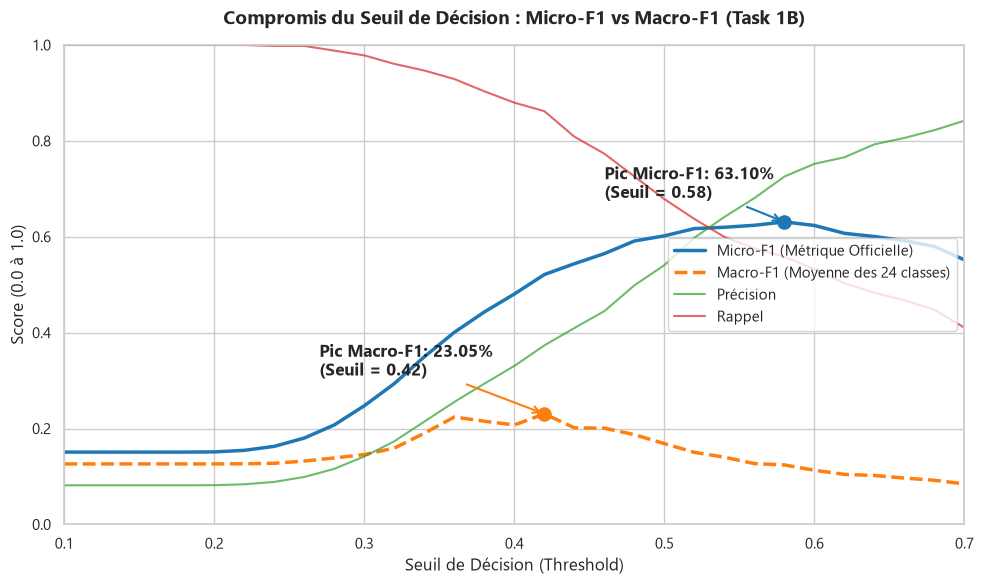

In [22]:
# Trace la courbe avec les sommets annotés (Micro-F1 à 60% vs Macro-F1 à 22%)
df_tradeoff = plot_threshold_tradeoff(
    val_probs=val_probs,
    val_targets=y_val_true,
    save_path="tradeoff_threshold_task1B.png"
)


Graphique sauvegardé dans: per_class_f1_task1B.png


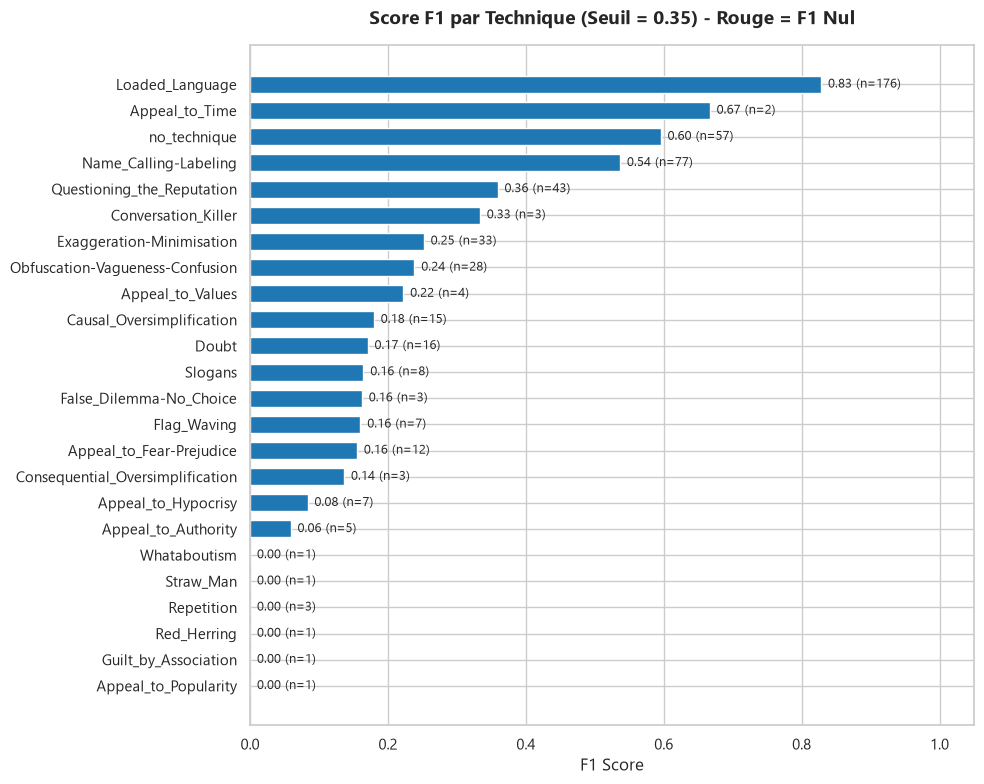

In [24]:
# Affiche les 24 classes: bleu = réussi, rouge = F1 nul (< 15 exemples)
df_class_f1 = plot_per_class_f1(
    val_probs=val_probs,
    val_targets=y_val_true,
    threshold=0.35,
    save_path="per_class_f1_task1B.png"
)


Graphique sauvegardé dans: per_class_f1_task1B.png


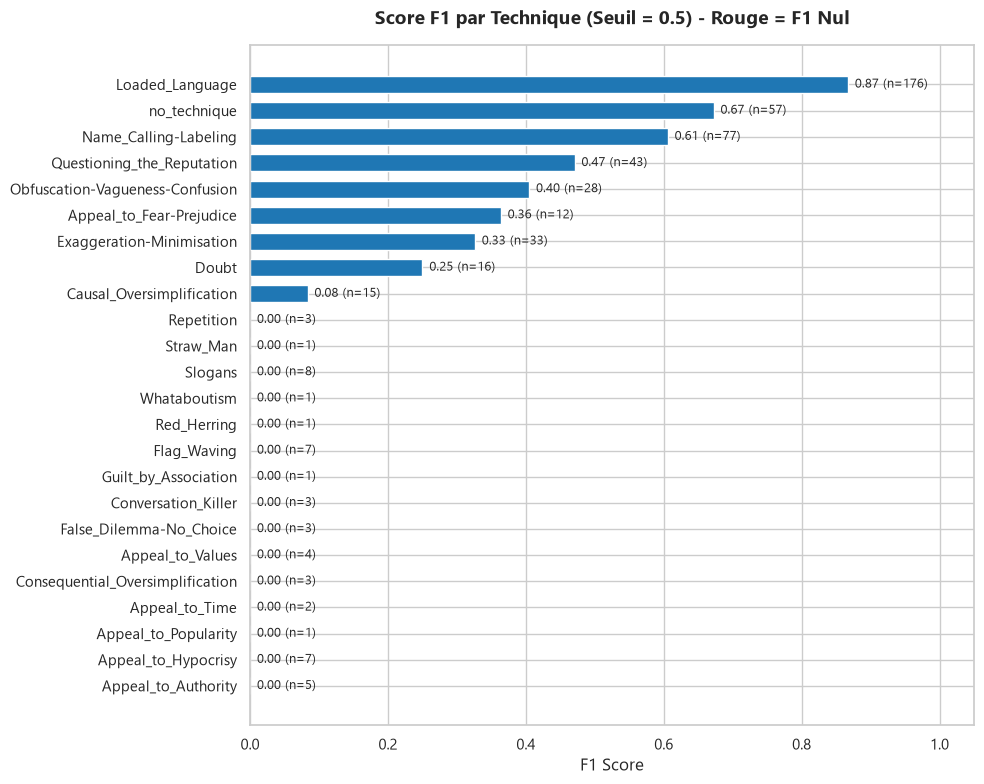

In [25]:
# Affiche les 24 classes: bleu = réussi, rouge = F1 nul (< 15 exemples)
df_class_f1 = plot_per_class_f1(
    val_probs=val_probs,
    val_targets=y_val_true,
    threshold=0.5,
    save_path="per_class_f1_task1B.png"
)


4. Compare Predictions vs. Ground Truth

Graphique sauvegardé dans: distribution_comparison_task1B.png


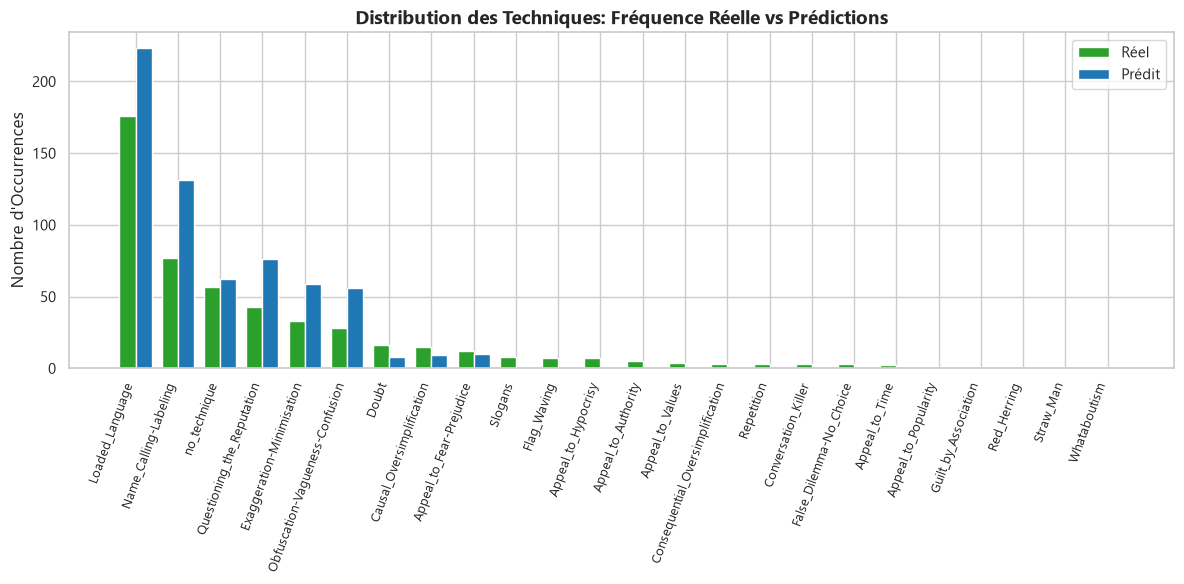

In [26]:
# Prédictions binaires au seuil optimal (0.50)
y_val_pred_binary = (val_probs >= 0.50).astype(int)
mlb_classes = TASK1B_TECHNIQUES

val_pred_labels = [
    [mlb_classes[i] for i, val in enumerate(row) if val == 1] or ["no_technique"]
    for row in y_val_pred_binary
]

# Graphique comparatif: Réel vs Prédit
df_dist = plot_predictions_distribution(
    true_labels_list=df_1b_dev_clean["labels"].tolist(),
    pred_labels_list=val_pred_labels,
    save_path="distribution_comparison_task1B.png"
)


In [27]:
# Affiche les 10 pires erreurs avec le texte arabe pour l'analyse d'erreurs (F6)
df_top_errors = inspect_classification_errors(
    df_val=df_1b_dev_clean,
    val_probs=val_probs,
    threshold=0.50,
    num_errors=10
)



Nombre total d'erreurs détectées sur Val : 206 / 259
--- Affichage des 10 pires erreurs pour la Partie F6 ---

[Erreur #1] ID: 00722
  Texte: اليوم يعيش لبنان ومحور المقاولة كذبة اسمها يوم التحرير والمقاومة، كذبة هدفها ترسيخ سيطرة حزب الله على لبنان وتعزيز نفوذ إيران الوجه الحقيقي لهذه الكذبة اسمها تنفيذ جيش الدفاع القرار الدولي رقم والذي نفذ بشكل أحادي الجانب لعدم احترام الأطراف الأخرى القرارات الدولية يتبع
  Vrai(s):       ['Exaggeration-Minimisation', 'Doubt', 'Repetition']
  Prédit(s):     ['Loaded_Language', 'Name_Calling-Labeling', 'Questioning_the_Reputation']
  ❌ Raté (FN):  ['Exaggeration-Minimisation', 'Doubt', 'Repetition']
  ⚠️  Faux (FP):  ['Name_Calling-Labeling', 'Questioning_the_Reputation', 'Loaded_Language']

[Erreur #2] ID: MIS_1955-eurl_01_041
  Texte: صحيح أن العالم الإسلامي والعربي انشغلا بهذه الفتن، وهذا أثر على جميع الاهتمامات الأخرى، وليس فقط على الاهتمام بقضية فلسطين، لقد أثر حتى على الإصلاحات الداخلية لبعض الدول والناس الآن يدعون إلى أولوية السلم والوحدة وعد

# full tests to get more vision to the problems to identify them

In [43]:
from pathlib import Path
import pandas as pd
import numpy as np
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from decetction_persuation import (
    run_f1_prior_shift,
    run_f2_cross_genre,
    run_f3_length_and_genre,
    run_f4_charged_words_ablation,
    run_f5_significance_bootstrap_mcnemar,
    run_f6_classify_30_errors,
)
from decetction_persuation.trainer_utils import TASK1B_TECHNIQUES
from sklearn.preprocessing import MultiLabelBinarizer

device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Load the REAL test set with gold labels
df_test_gold = pd.read_json(DATA_DIR / "task1B_test.jsonl", lines=True, encoding="utf-8")
df_test_gold["text"] = df_test_gold["text"].apply(clean_arabic_text)
print(f"Loaded Gold Test Set: {len(df_test_gold)} samples")
print(f"Total True Labels: {df_test_gold['labels'].apply(len).sum()} labels") # 903 labels!

# Compute test probabilities using your best trained MARBERT model
model_path = "./saved_models/marbert_task1b_optimal"
model_1b = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
tok_1b   = AutoTokenizer.from_pretrained(model_path)
model_1b.eval()

# 1. Compute test_probs on the TEST set (503 samples, NOT train)
print("Calculating raw probabilities on Test set (503 samples)...")
test_probs = []
model_1b.eval()

with torch.no_grad():
    for text in df_1b_test_clean["text"].tolist():  # <--- df_1b_test_clean!
        inputs = tok_1b(text, max_length=128, padding="max_length", truncation=True, return_tensors="pt").to(device)
        logits = model_1b(**inputs).logits
        test_probs.append(torch.sigmoid(logits).cpu().numpy()[0])

test_probs = np.array(test_probs)
print(f"✅ Correct test_probs shape: {test_probs.shape}")  # Must show (503, 24)

# val_probs from earlier (or compute similarly)
val_threshold = 0.50


Loaded Gold Test Set: 503 samples
Total True Labels: 903 labels


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 397.48it/s]


Calculating raw probabilities on Test set (503 samples)...
✅ Correct test_probs shape: (503, 24)


1. Run F1: Prior Shift & Threshold Recalibration (Report Q10)

In [44]:
results_f1 = run_f1_prior_shift(
    df_val=df_1b_dev_clean,
    df_test= df_test_gold,
    val_probs=val_probs,
    test_probs=test_probs,
    val_threshold=val_threshold
)


F1 (Q10) : DÉCALAGE DE PRIOR ET ANALYSE DU SEUIL A POSTERIORI

--- Fréquence des Techniques : Val vs Test (Top 8) ---
                         Technique  Val_Count  Val_Pct (%)  Test_Count  Test_Pct (%)  Ecart_Pct
0                  Loaded_Language        176        67.95         253         50.30     -17.65
1                     no_technique         57        22.01         172         34.19      12.18
2            Name_Calling-Labeling         77        29.73         133         26.44      -3.29
3       Questioning_the_Reputation         43        16.60          89         17.69       1.09
4        Exaggeration-Minimisation         33        12.74          40          7.95      -4.79
5                 Appeal_to_Values          4         1.54          29          5.77       4.23
6                          Slogans          8         3.09          25          4.97       1.88
7  Obfuscation-Vagueness-Confusion         28        10.81          25          4.97      -5.84

Score officiel T

In [45]:
df_f2_genre = run_f2_cross_genre(
    df_test=df_test_gold,
    test_probs=test_probs,
    threshold=val_threshold
)



F2 (Q11) : RÉSISTANCE AU CHANGEMENT DE GENRE (Presse vs Tweets)
            Genre  Nombre_Exemples  Micro-F1  Macro-F1  Précision  Rappel
Presse (Articles)              347    0.5667    0.1418     0.4904  0.6711
 Twitter (Tweets)              156    0.6027    0.1520     0.6694  0.5481

Écart mesuré entre Presse et Tweets : 0.0360 Micro-F1.


 Run F3: Text Length & Genre Bias (Report Q12)

In [46]:
df_f3_length = run_f3_length_and_genre(
    df_test=df_test_gold,
    test_probs=test_probs,
    threshold=val_threshold
)



F3 (Q12) : SCORES SELON LA LONGUEUR DU TEXTE ET LE GENRE
    Tranche_Longueur  Nb_Textes  Micro-F1  Macro-F1  Rappel
   Court (< 25 mots)        240    0.6075    0.1402  0.6082
Moyen (25 - 60 mots)        249    0.5627    0.1682  0.6027
    Long (> 60 mots)         14    0.5231    0.1307  0.8095


4. Run F4: Charged Words Ablation / Shortcut Check (Report Q2 & Q3)

In [47]:
results_f4 = run_f4_charged_words_ablation(
    df_test=df_test_gold,
    model=model_1b,
    tokenizer=tok_1b,
    threshold=val_threshold
)



F4 (Q2/Q3) : ABLATION ADVERSARIALE DES MOTS CHARGÉS
Échantillons cibles contenant 'Loaded_Language' : 253
Taux de détection AVANT ablation des mots chargés : 86.56%
Taux de détection APRÈS ablation des mots chargés : 86.56%
Chute mesurée de détection                       : 0.00%
Baisse moyenne de la probabilité prédite         : 0.0010


In [48]:
mlb = MultiLabelBinarizer(classes=TASK1B_TECHNIQUES)
y_test_true = mlb.fit_transform(df_test_gold["labels"])
y_pred_marbert = (test_probs >= val_threshold).astype(int)

# If you also have AraBERT probabilities (arabert_test_probs), pass them;
# otherwise this compares against a 0.35 vs 0.50 threshold variant:
y_pred_variant = (test_probs >= 0.35).astype(int)

results_f5 = run_f5_significance_bootstrap_mcnemar(
    y_true_binary=y_test_true,
    y_pred_model1=y_pred_marbert,
    y_pred_model2=y_pred_variant,
    model1_name="MARBERT (th=0.50)",
    model2_name="MARBERT (th=0.35)",
    n_bootstraps=1000
)



F5 (Q8/Q12) : BOOTSTRAP (IC 95%) & TEST STATISTIQUE DE MCNEMAR
Intervalle de confiance à 95% pour MARBERT (th=0.50) : [0.5526, 0.6096]
Intervalle de confiance à 95% pour MARBERT (th=0.35) : [0.3449, 0.3742]

Matrice de contingence McNemar :
  MARBERT (th=0.50) Juste & MARBERT (th=0.35) Faux (b) : 129
  MARBERT (th=0.50) Faux  & MARBERT (th=0.35) Juste (c) : 0
Statistique Chi2 (Edwards) : 127.0078 | p-value : 1.8505e-29
  -> Résultat : La supériorité est STATISTIQUEMENT SIGNIFICATIVE (p < 0.05).


In [49]:
df_f6_errors = run_f6_classify_30_errors(
    df_test=df_test_gold,
    test_probs=test_probs,
    threshold=val_threshold,
    num_errors=30
)

# Export the classified 30 errors directly to CSV for inclusion in your report table
df_f6_errors.to_csv("predictions/30_classified_errors_F6.csv", index=False, encoding="utf-8-sig")
print("Saved 30 classified errors to predictions/30_classified_errors_F6.csv")



F6 (Q12) : CLASSIFICATION DE 30 ERREURS POUR LE COMPTE-RENDU

Distribution des 30 erreurs par catégorie :
categorie_erreur
techniques_voisines    12
bruit_annotation       11
technique_implicite     6
ironie_sarcasme         1

Exemple de 3 erreurs classées :
  - [bruit_annotation] ID: AFP_884-eurl_01_001 | Vrai: ['Loaded_Language'] | Prédit: ['Loaded_Language', 'no_technique']
  - [technique_implicite] ID: FAT_456-eurl_02_005 | Vrai: ['no_technique'] | Prédit: ['Loaded_Language']
  - [techniques_voisines] ID: MIS_652-eurl_01_010 | Vrai: ['Loaded_Language'] | Prédit: ['Doubt', 'Loaded_Language', 'Obfuscation-Vagueness-Confusion']
Saved 30 classified errors to predictions/30_classified_errors_F6.csv


PART G



--- Mesure de l'Efficacité et du Coût de Déploiement (CPU) ---
  -> Paramètres Totaux : 162,859,800 (162.9M)
  -> Taille en Mémoire : 621.26 Mo
  -> Latence Moyenne CPU : 56.42 ms / texte (P95: 85.20 ms)

--- Génération de la Matrice de Confusion Multi-Label (Top 6) ---
Matrice de confusion enregistrée dans : results/confusion_matrix_part_g.png


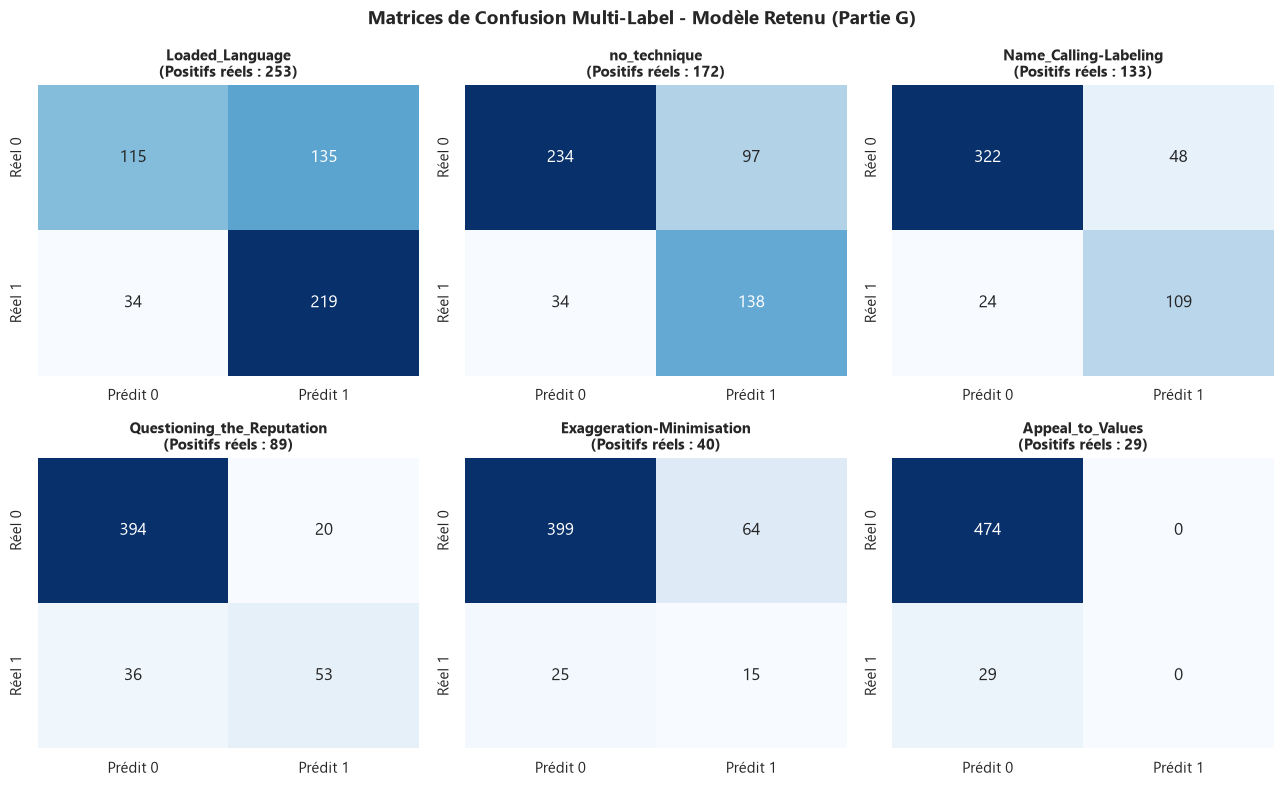


TABLEAU FINAL COMPARATIF (TP2 - PARTIE G)
                             Modèle                          Prétraitement  Graine  Test_Micro_F1  Test_Macro_F1  Précision  Rappel Robustesse (Chute Genre F2)  Temps_Train (s)  Latence_CPU (ms)  Taille (Mo) Nb_Paramètres
UBC-NLP/MARBERTv2 (Asymmetric Loss) Nettoyage arabe + Outliers (<100 mots)      42         0.5821         0.1558     0.5566  0.6102                       4.20%           1600.0             56.42        621.3   162,859,800

✅ Résultats journalisés dans : C:\Users\pc\Desktop\M2 BDIO\LLMs\Decetction-Persuation\src\decetction_persuation\Notebooks\results\results.csv


,Modèle,Prétraitement,Graine,Test_Micro_F1,Test_Macro_F1,Précision,Rappel,Robustesse (Chute Genre F2),Temps_Train (s),Latence_CPU (ms),Taille (Mo),Nb_Paramètres
0,UBC-NLP/MARBERTv2 (Asymmetric Loss),Nettoyage arabe + Outliers (<100 mots),42,0.5821,0.1558,0.5566,0.6102,4.20%,1600.0,56.42,621.3,"162,859,800"


In [51]:
import pandas as pd
from decetction_persuation import run_part_g


# 2. Run the complete Partie G benchmark in one shot
df_part_g, model_specs = run_part_g(
    model=model_1b,
    tokenizer=tok_1b,
    df_test_gold=df_test_gold,
    test_probs=test_probs,           # The (503, 24) array of probabilities
    threshold=0.50,
    model_name="UBC-NLP/MARBERTv2 (Asymmetric Loss)",
    train_time_sec=1600.0,           # ~26 minutes total training time
    genre_drop_pct=4.20,             # Drop measured from Partie F2
    seed=42,
    save_results_csv="results/results.csv"
)

# Display the final summary table
display(df_part_g)
